## IMPORTS

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import yfinance as yf
from datetime import datetime, timedelta
import logging
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')


## CONFIG

In [2]:
MONGO_URI = os.getenv("MONGODB_URI_FUTURES_3", "")  # Reemplaza con tu URI o defínela en .env
MONGO_DB = os.getenv("MONGODB_DB", "market_data")

#Only put the name of the instrument here, the rest will be generated automatically
INSTRUMENT = "NQ"

COLLECTION_NAME = f"{INSTRUMENT.lower()}_15min"
CSV_15MIN = f"{INSTRUMENT.lower()}_15min_full.csv"
CSV_1H = f"{INSTRUMENT.lower()}_1h_full.csv"
CSV_4H = f"{INSTRUMENT.lower()}_4h_full.csv"
CSV_1D = f"{INSTRUMENT.lower()}_1d.csv" 
VALIDATION_REPORT_1H = f"{INSTRUMENT.lower()}_1h_validation_report.txt"
VALIDATION_REPORT_4H = f"{INSTRUMENT.lower()}_4h_validation_report.txt"
YAHOO_SYMBOL = f"{INSTRUMENT.upper()}=F"
INTRADAY_DAYS = 60

## MONGO DB CONNECTION AND FETCH MONGODB

In [3]:

import logging
from utils import load_data_from_mongo   

logging.basicConfig(level=logging.INFO)

URI_ENV = 'MONGODB_URI_FUTURES_3'     
DB_ENV = 'MONGODB_DB'                 
DEFAULT_DB = 'market_data'           
DATE_FIELD = 'timestamp'             

try:
    df_raw = load_data_from_mongo(
        collection_name=COLLECTION_NAME,
        uri_env=URI_ENV,
        db_name_env=DB_ENV,
        default_db=DEFAULT_DB,
        date_field=DATE_FIELD
    )
    
    logging.info(f"✅ Cargados {len(df_raw):,} registros de 15 minutos.")
    logging.info(f"   Rango: {df_raw.index.min()} -> {df_raw.index.max()}")

except Exception as e:
    logging.error(f"❌ Error al cargar datos: {e}")
    raise   

2026-08-24 16:48:08,641 - INFO - ✅ Cargados 397,370 registros de 15 minutos.
2026-08-24 16:48:08,644 - INFO -    Rango: 2009-09-27 18:00:00 -> 2026-08-21 16:45:00


## RESAMPLE A 1H, 4H Y 1D

In [4]:
logging.info("Resampling to 1-hour candles...")
df_raw.index.name = 'timestamp'
df_1h = df_raw.resample('1h').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna().reset_index()
logging.info(f"1-hour candles: {len(df_1h):,} records.")
logging.info(f"   Range: {df_1h['timestamp'].min()} -> {df_1h['timestamp'].max()}")

logging.info("Resampling to 4-hour candles...")
df_4h = df_raw.resample('4h').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna().reset_index()
logging.info(f"4-hour candles: {len(df_4h):,} records.")
logging.info(f"   Range: {df_4h['timestamp'].min()} -> {df_4h['timestamp'].max()}")

logging.info("Resampling to daily candles (1D)...")
df_daily = df_raw.resample('D').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna().reset_index()
logging.info(f"Daily candles: {len(df_daily):,} records.")
logging.info(f"   Range: {df_daily['timestamp'].min()} -> {df_daily['timestamp'].max()}")

2026-08-24 16:48:08,662 - INFO - Resampling to 1-hour candles...
2026-08-24 16:48:08,706 - INFO - 1-hour candles: 101,113 records.
2026-08-24 16:48:08,708 - INFO -    Range: 2009-09-27 18:00:00 -> 2026-08-21 16:00:00
2026-08-24 16:48:08,709 - INFO - Resampling to 4-hour candles...
2026-08-24 16:48:08,745 - INFO - 4-hour candles: 26,996 records.
2026-08-24 16:48:08,746 - INFO -    Range: 2009-09-27 16:00:00 -> 2026-08-21 16:00:00
2026-08-24 16:48:08,746 - INFO - Resampling to daily candles (1D)...
2026-08-24 16:48:08,757 - INFO - Daily candles: 5,256 records.
2026-08-24 16:48:08,760 - INFO -    Range: 2009-09-27 00:00:00 -> 2026-08-21 00:00:00


## SAVE TO CSV

In [5]:
df_raw.to_csv(CSV_15MIN, index=False)
logging.info(f"✅ Datos de 15 minutos guardados en '{CSV_15MIN}' ({len(df_raw):,} filas).")

df_1h.to_csv(CSV_1H, index=False)
logging.info(f"✅ Datos de 1 hora guardados en '{CSV_1H}' ({len(df_1h):,} filas).")

df_4h.to_csv(CSV_4H, index=False)
logging.info(f"✅ Datos de 4 horas guardados en '{CSV_4H}' ({len(df_4h):,} filas).")

df_daily.to_csv(CSV_1D, index=False)
logging.info(f"✅ Datos diarios guardados en '{CSV_1D}' ({len(df_daily):,} filas).")

2026-08-24 16:48:09,632 - INFO - ✅ Datos de 15 minutos guardados en 'nq_15min_full.csv' (397,370 filas).
2026-08-24 16:48:09,949 - INFO - ✅ Datos de 1 hora guardados en 'nq_1h_full.csv' (101,113 filas).
2026-08-24 16:48:10,020 - INFO - ✅ Datos de 4 horas guardados en 'nq_4h_full.csv' (26,996 filas).
2026-08-24 16:48:10,035 - INFO - ✅ Datos diarios guardados en 'nq_1d.csv' (5,256 filas).


## VALIDATION FUNCTION

In [ ]:
def validate_against_yahoo(df_resampled, label, report_filename, yahoo_symbol=YAHOO_SYMBOL, intraday_days=INTRADAY_DAYS):
    logging.info(f"Validating {label} data...")

    df_daily = df_resampled.resample('D', on='timestamp').agg({'close': 'last'}).dropna()
    df_daily.index = df_daily.index.tz_localize(None)

    start_date = df_daily.index.min().date()
    end_date = df_daily.index.max().date()

    logging.info(f"Downloading daily reference from Yahoo ({yahoo_symbol})...")
    df_yahoo = yf.download(yahoo_symbol, start=start_date, end=end_date, interval='1d', progress=False)

    if df_yahoo.empty:
        logging.error("Could not get daily reference. Validation skipped.")
        return False

    df_yahoo.index = pd.to_datetime(df_yahoo.index).tz_localize(None)
    yahoo_close = df_yahoo['Close']

    common_dates = pd.Index(df_daily.index).intersection(yahoo_close.index).sort_values()

    if len(common_dates) < 3:
        logging.warning("Too few common dates for daily validation.")
        return False

    our_prices = np.ravel(df_daily.reindex(common_dates)['close'].values)
    ref_prices = np.ravel(yahoo_close.reindex(common_dates).values)

    mask = ~(np.isnan(our_prices) | np.isnan(ref_prices))
    our_prices, ref_prices = our_prices[mask], ref_prices[mask]

    if len(our_prices) < 3:
        logging.warning("Too few valid points after cleaning NaNs.")
        return False

    corr = np.corrcoef(our_prices, ref_prices)[0, 1]
    mae = np.mean(np.abs(our_prices - ref_prices))
    max_diff = np.max(np.abs(our_prices - ref_prices))

    print(f"\nDAILY VALIDATION - {label}")
    print("="*60)
    print(f"Correlation:         {corr:.6f}")
    print(f"Mean Absolute Error: {mae:.4f} points")
    print(f"Maximum Difference:  {max_diff:.4f} points")
    print("="*60)

    diaria_passed = corr > 0.99
    status = "PASSED" if diaria_passed else "WARNING – Correlation < 0.99"
    print(f"Status: {status}")

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(df_daily.index, df_daily['close'], label=f'{label} (daily aggregated)', linewidth=1.5, color='blue')
    ax.plot(yahoo_close.index, yahoo_close, label=f'Yahoo Finance ({yahoo_symbol})', linewidth=1.5, color='red', alpha=0.7, linestyle='--')
    ax.set_title(f'{label} vs Yahoo Daily\nCorrelation: {corr:.6f}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Price')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    logging.info(f"Intraday direct validation for {label} (last {intraday_days} days)...")
    end_intra = datetime.now()
    start_intra = end_intra - timedelta(days=intraday_days)

    df_recent = df_resampled[(df_resampled['timestamp'] >= start_intra) & (df_resampled['timestamp'] <= end_intra)]
    if df_recent.empty:
        logging.warning("No recent data for intraday validation.")
    else:
        logging.info(f"Downloading 1H intraday data from Yahoo ({yahoo_symbol})...")
        df_yahoo_intra = yf.download(yahoo_symbol, start=start_intra, end=end_intra, interval="1h", progress=False)

        if not df_yahoo_intra.empty:
            df_yahoo_intra.index = pd.to_datetime(df_yahoo_intra.index).tz_localize(None)

            if label == "4H":
                logging.info("   Resampling Yahoo 1H -> 4H...")
                df_yahoo_intra = df_yahoo_intra.resample('4H').agg({
                    'Open': 'first',
                    'High': 'max',
                    'Low': 'min',
                    'Close': 'last',
                    'Volume': 'sum'
                }).dropna()

            common_ts = pd.Index(df_recent['timestamp']).intersection(df_yahoo_intra.index).sort_values()

            if len(common_ts) > 5:
                our_intra = np.ravel(df_recent.set_index('timestamp').reindex(common_ts)['close'].values)
                ref_intra = np.ravel(df_yahoo_intra.reindex(common_ts)['Close'].values)

                mask = ~(np.isnan(our_intra) | np.isnan(ref_intra))
                our_intra, ref_intra = our_intra[mask], ref_intra[mask]

                if len(our_intra) > 5:
                    corr_intra = np.corrcoef(our_intra, ref_intra)[0, 1]
                    mae_intra = np.mean(np.abs(our_intra - ref_intra))
                    max_diff_intra = np.max(np.abs(our_intra - ref_intra))

                    print(f"\nINTRADAY VALIDATION - {label} (last {intraday_days} days)")
                    print("="*60)
                    print(f"Intraday correlation: {corr_intra:.6f}")
                    print(f"Mean Absolute Error:  {mae_intra:.4f} points")
                    print(f"Maximum Difference:   {max_diff_intra:.4f} points")
                    print("="*60)
                    intra_passed = corr_intra > 0.99
                    print(f"Status: {'PASSED' if intra_passed else 'WARNING'}")
                else:
                    logging.warning("Too few common points for intraday validation after cleaning NaNs.")
            else:
                logging.warning("Not enough common timestamps for intraday validation.")
        else:
            logging.warning("Yahoo returned no intraday data.")

    with open(report_filename, 'w') as f:
        f.write(f"{label} Data Validation Report\n")
        f.write(f"{'='*60}\n")
        f.write(f"Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write(f"Data period: {start_date} -> {end_date}\n")
        f.write(f"Total {label} candles: {len(df_resampled)}\n")
        f.write(f"Common dates with Yahoo (daily): {len(common_dates)}\n")
        f.write(f"Correlation (daily): {corr:.6f}\n")
        f.write(f"Mean Absolute Error: {mae:.4f}\n")
        f.write(f"Maximum Difference: {max_diff:.4f}\n")
        f.write(f"Status: {status}\n")
    logging.info(f"Report saved to '{report_filename}'.")

    return diaria_passed

## VALIDATION 1H

2026-08-24 16:48:10,089 - INFO - Validating 1H data...
2026-08-24 16:48:10,312 - INFO - Downloading daily reference from Yahoo (NQ=F)...



DAILY VALIDATION - 1H
Correlation:         0.999965
Mean Absolute Error: 27.6542 points
Maximum Difference:  731.0000 points
Status: PASSED


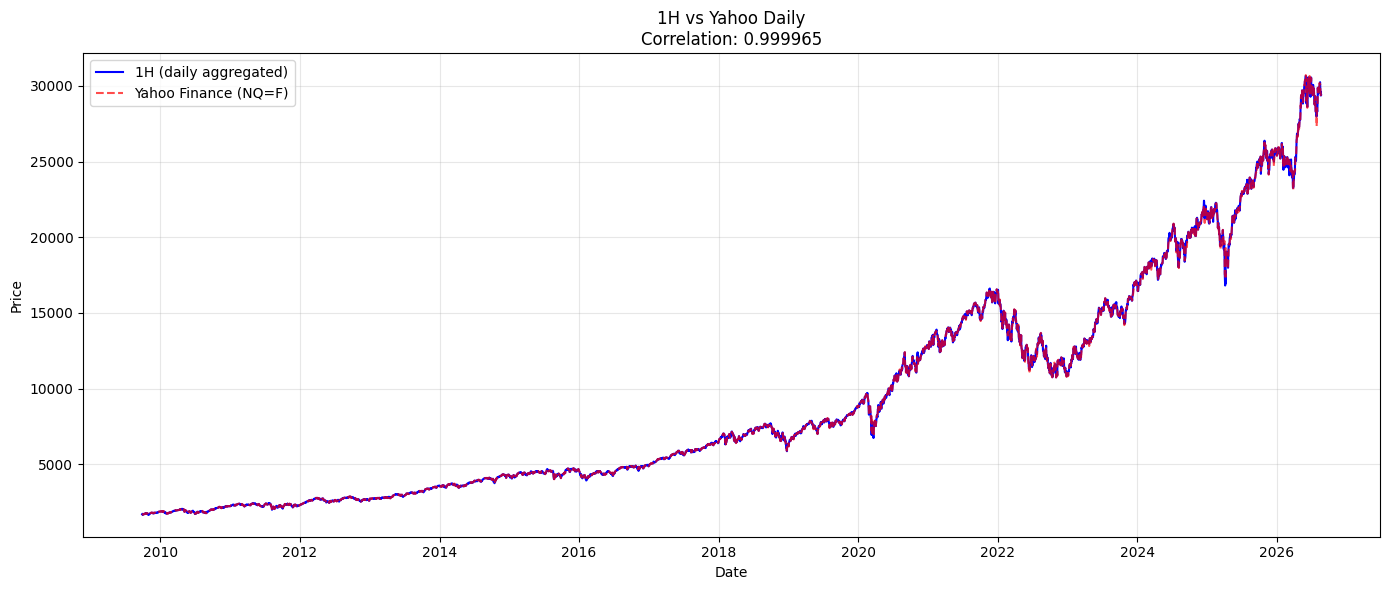

2026-08-24 16:48:11,722 - INFO - Intraday direct validation for 1H (last 60 days)...
2026-08-24 16:48:11,733 - INFO - Downloading 1H intraday data from Yahoo (NQ=F)...
2026-08-24 16:48:12,153 - INFO - Report saved to 'nq_1h_validation_report.txt'.



INTRADAY VALIDATION - 1H (last 60 days)
Intraday correlation: 0.955177
Mean Absolute Error:  126.2810 points
Maximum Difference:   809.5000 points
Status: WARNING


In [7]:
validation_1h = validate_against_yahoo(df_1h, "1H", VALIDATION_REPORT_1H, YAHOO_SYMBOL, INTRADAY_DAYS)

## FINAL SUMMARY

In [8]:
print("\n" + "="*60)
print("EXPORT SUMMARY (15min, 1H, 4H, 1D)")
print("="*60)
print(f"Source collection:       {COLLECTION_NAME}")
print(f"Base data (15min):       {len(df_raw):,} records")
print(f"1H candles generated:    {len(df_1h):,}")
print(f"4H candles generated:    {len(df_4h):,}")
print(f"1D candles generated:    {len(df_daily):,}")
print(f"15min file:              {CSV_15MIN}")
print(f"1H file:                 {CSV_1H}")
print(f"4H file:                 {CSV_4H}")
print(f"1D file:                 {CSV_1D}")
print(f"1H validation:           {'PASSED' if validation_1h else 'CHECK'}")
print("="*60)


EXPORT SUMMARY (15min, 1H, 4H, 1D)
Source collection:       nq_15min
Base data (15min):       397,370 records
1H candles generated:    101,113
4H candles generated:    26,996
1D candles generated:    5,256
15min file:              nq_15min_full.csv
1H file:                 nq_1h_full.csv
4H file:                 nq_4h_full.csv
1D file:                 nq_1d.csv
1H validation:           PASSED
